# AML 3303 — MapleFreight Delivery Delay Prediction & Slack Alerts
 Narinder Kaur | **Student ID:** c0965335

## 1. Business context, problem and objectives
MapleFreight moves about 8,000 shipments weekly. On-time delivery performance has fallen from 94% to 88%, and dispatch often hears about delays from customers. We want to identify high-risk shipments early enough to intervene.

**Objectives:** explore drivers of delay; compare a baseline and machine-learning model; evaluate late-delivery recall and precision; explain predictions; alert dispatch through Slack; recommend improvements.

**Prediction moment:** at dispatch or after pickup when `pickup_delay_minutes` is available. `actual_transit_hours` is never available at this point and must not be used as a model input.

## 2. Import libraries and load data

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
DATA_PATH = "maplefreight_delivery_delay_dataset.csv"
df_raw = pd.read_csv(DATA_PATH)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())
df_raw.info()

Dataset shape: (6035, 23)


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   object 
 1   origin_city                6035 non-null   object 
 2   destination_city           6035 non-null   object 
 3   carrier                    6035 non-null   object 
 4   service_level              6035 non-null   object 
 5   goods_type                 6035 non-null   object 
 6   customer_priority_tier     6035 non-null   object 
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float

## 3. Data understanding and quality checks

In [ ]:
print("Missing values:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing"))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate shipment IDs:", df_raw.shipment_id.duplicated().sum())
print("Target counts:")
display(df_raw.delivered_late.value_counts().rename(index={0:"On time",1:"Late"}))
display(df_raw.describe(include="all").T)

Missing values:


,missing
fuel_cost_cad,240
driver_experience_years,210
weather_condition,150
traffic_index,121
shipment_id,0
origin_city,0
destination_city,0
customer_priority_tier,0
goods_type,0
service_level,0


Exact duplicate rows: 32
Duplicate shipment IDs: 35
Target counts:


delivered_late
On time    4793
Late       1242
Name: count, dtype: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
shipment_id,6035,6000,SHP-100905,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin_city,6035,7,Toronto ON,1593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,6035,10,Sudbury ON,641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
carrier,6035,5,MapleFreight Fleet,2391,NaN,NaN,NaN,NaN,NaN,NaN,NaN
service_level,6035,6,Standard,3219,NaN,NaN,NaN,NaN,NaN,NaN,NaN
goods_type,6035,5,General Freight,2974,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_priority_tier,6035,3,Silver,2775,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipment_month,6035.0,NaN,NaN,NaN,6.543662,3.44826,1.0,4.0,7.0,10.0,12.0
distance_km,6035.0,NaN,NaN,NaN,632.192742,319.246133,80.5,398.6,571.1,804.85,2556.7
weight_kg,6035.0,NaN,NaN,NaN,6928.251135,83755.149685,30.0,496.0,827.1,1286.3,2999300.0


## Data Understanding

The original dataset contains **6,035 shipments and 23 columns**. It includes information about shipment locations, carriers, weather conditions, traffic, delivery times, and other factors that may affect delivery performance.

During the initial data quality check, I found:

- 240 missing values in `fuel_cost_cad`.
- 210 missing values in `driver_experience_years`.
- 150 missing values in `weather_condition`.
- 121 missing values in `traffic_index`.
- 32 exact duplicate rows.
- 35 repeated shipment IDs before cleaning.

The dataset contains 4,793 on-time deliveries and 1,242 late deliveries. This means approximately **20.6% of shipments were late**.

This shows that the dataset is imbalanced because there are more on-time shipments than late shipments. Therefore, accuracy alone will not be enough to evaluate the machine learning models.

Before building the models, I need to clean the data to make the predictions more reliable.

## 4. Data cleaning — fix text, duplicates and unit errors

This is important because dataset contains missing values, duplicates, inconsistent spellings and possible unit errors.

In [ ]:
df = df_raw.drop_duplicates().copy()
# Inspect repeated IDs: do not arbitrarily discard conflicting records.
repeated = df[df.duplicated("shipment_id", keep=False)].sort_values("shipment_id")
print("Rows with repeated IDs after exact deduplication:", len(repeated))
display(repeated[["shipment_id", "delivered_late"]].head(12))
# Drop ambiguous IDs only if records conflict; document the decision.
conflicting_ids = repeated.shipment_id.unique()
if len(conflicting_ids):
    df = df[~df.shipment_id.isin(conflicting_ids)].copy()
    print("Excluded ambiguous shipment IDs:", len(conflicting_ids))
text_cols = df.select_dtypes(include="object").columns.drop("shipment_id")
for col in text_cols:
    df[col] = df[col].str.strip().str.lower()
print("Service levels:", df.service_level.value_counts().to_dict())
print("Weights above 30,000 kg:", (df.weight_kg > 30000).sum())
display(df.loc[df.weight_kg > 30000, ["shipment_id", "weight_kg"]].head(12))

Rows with repeated IDs after exact deduplication: 6


,shipment_id,delivered_late
861,SHP-101906,0
3030,SHP-101906,0
1228,SHP-102476,1
4033,SHP-102476,1
441,SHP-103022,0
4375,SHP-103022,0


Excluded ambiguous shipment IDs: 3
Service levels: {'standard': 3273, 'express': 1459, 'economy': 1265}
Weights above 30,000 kg: 40


,shipment_id,weight_kg
666,SHP-102849,1121100.0
696,SHP-100641,1332200.0
846,SHP-101687,1593600.0
865,SHP-105182,555500.0
943,SHP-100519,285200.0
977,SHP-104825,760200.0
998,SHP-102703,362100.0
1030,SHP-102384,1209400.0
1324,SHP-102735,618400.0
1525,SHP-102395,1554700.0


###  Data Cleaning

I cleaned the dataset to improve its quality before using it for machine learning.

First, I removed 32 exact duplicate records. I also identified three shipment IDs that were repeated with different records and excluded these ambiguous shipments.

Next, I standardized inconsistent category names, including service levels, so that similar values would be treated as one category.

I also found 40 shipment weights that appeared to be recorded in grams instead of kilograms. These values were converted to kilograms by dividing them by 1,000.

After cleaning, the dataset contained **5,997 shipments and 23 original columns**.

Missing values were handled later through the preprocessing pipeline using imputation methods.

Overall, these cleaning steps helped make the dataset more consistent and suitable for training machine learning models.

In [ ]:
# Dataset contains some weights 1,000 times too large; correct clearly implausible values.
# Check the affected records in the output above before using this rule.
weight_fix_mask = df.weight_kg > 30000
if weight_fix_mask.any():
    df.loc[weight_fix_mask, "weight_kg"] /= 1000
    print("Weights converted from grams to kilograms:", weight_fix_mask.sum())
# Invalid values become missing and are imputed *inside* the training pipeline.
valid_ranges = {
    "distance_km": (0, np.inf), "weight_kg": (0, np.inf),
    "scheduled_transit_hours": (0, np.inf), "driver_experience_years": (0, 70),
    "vehicle_age_years": (0, 80), "traffic_index": (0, 100),
    "route_congestion_score": (0, 1), "fuel_cost_cad": (0, np.inf),
    "shipment_month": (1, 12), "num_stops": (0, np.inf),
    "prior_late_deliveries_30d": (0, np.inf)
}
for col, (lo, hi) in valid_ranges.items():
    invalid = df[col].notna() & ((df[col] < lo) | (df[col] > hi) | ((col in ["distance_km", "weight_kg", "scheduled_transit_hours"]) & (df[col] == 0)))
    if invalid.any():
        print("Invalid", col, ":", invalid.sum())
        df.loc[invalid, col] = np.nan
print("Cleaned shape:", df.shape)

Weights converted from grams to kilograms: 40
Cleaned shape: (5997, 23)


## 5. Exploratory data analysis (EDA)

EDA means exploring the dataset using graphs and statistics to understand patterns.

###  Delivery Status and Pickup Delays

The first graph compares on-time and late deliveries. It shows that most shipments were delivered on time, while approximately 21% were late.

This confirms that the dataset is imbalanced. A model that always predicts "on time" could achieve relatively high accuracy without identifying any late deliveries.

The second graph compares pickup delays between on-time and late shipments. It helps us understand whether delays occurring at pickup may be related to the final delivery status.

Pickup delays are an important factor to investigate because a shipment that starts late may have less time to reach its destination before the promised delivery window.

These graphs show why it is important to examine operational factors instead of relying only on the overall delivery status.

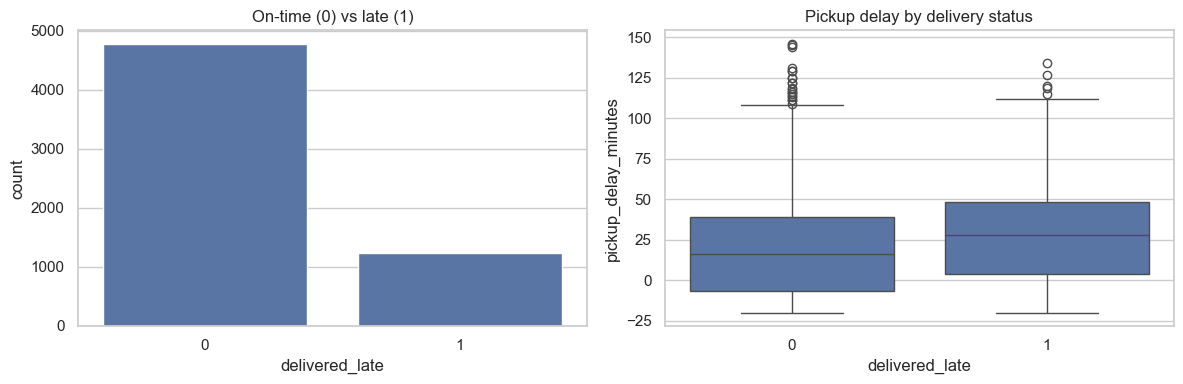

Late rate by weather_condition


,mean,count
weather_condition,,
storm,0.464286,280
snow,0.336806,864
NaN,0.220000,150
fog,0.210024,419
rain,0.207391,1326
clear,0.140636,2958


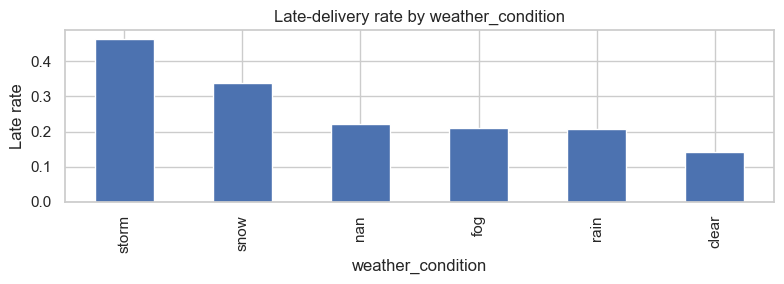

Late rate by carrier


,mean,count
carrier,,
contract owner-op,0.360709,621
prairieline,0.264293,927
quebecexpress,0.224044,915
northstar carriers,0.219723,1156
maplefreight fleet,0.128259,2378


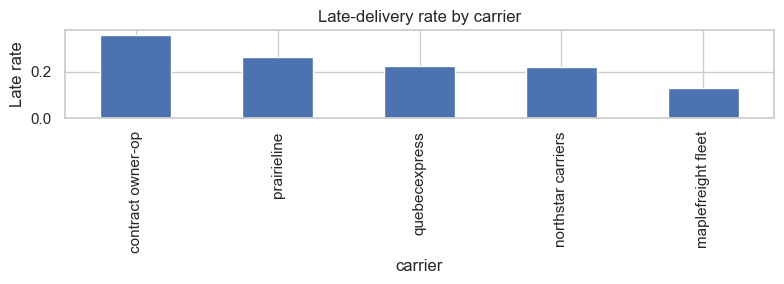

Late rate by service_level


,mean,count
service_level,,
economy,0.265613,1265
standard,0.206844,3273
express,0.150788,1459


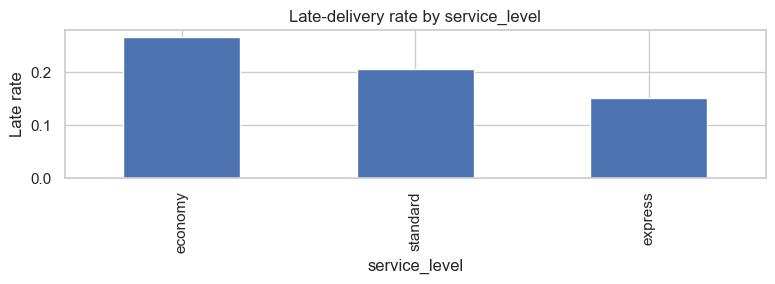

Late rate by customer_priority_tier


,mean,count
customer_priority_tier,,
gold,0.207223,1163
bronze,0.206548,2077
silver,0.204207,2757


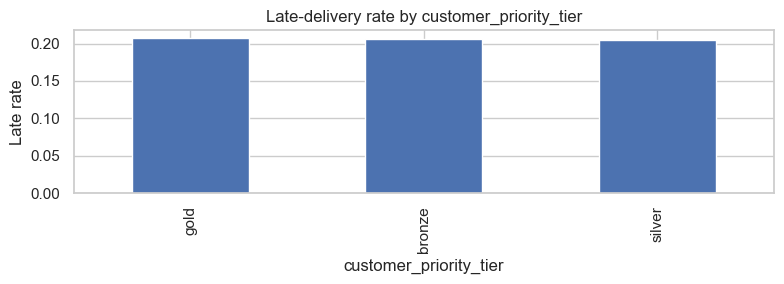

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="delivered_late", ax=axes[0]); axes[0].set_title("On-time (0) vs late (1)")
sns.boxplot(data=df, x="delivered_late", y="pickup_delay_minutes", ax=axes[1]); axes[1].set_title("Pickup delay by delivery status")
plt.tight_layout(); plt.show()
for col in ["weather_condition", "carrier", "service_level", "customer_priority_tier"]:
    rates = df.groupby(col, dropna=False)["delivered_late"].agg(["mean", "count"]).sort_values("mean", ascending=False)
    print("Late rate by", col)
    display(rates)
    rates["mean"].plot(kind="bar", title=f"Late-delivery rate by {col}", ylabel="Late rate", figsize=(8,3))
    plt.tight_layout(); plt.show()

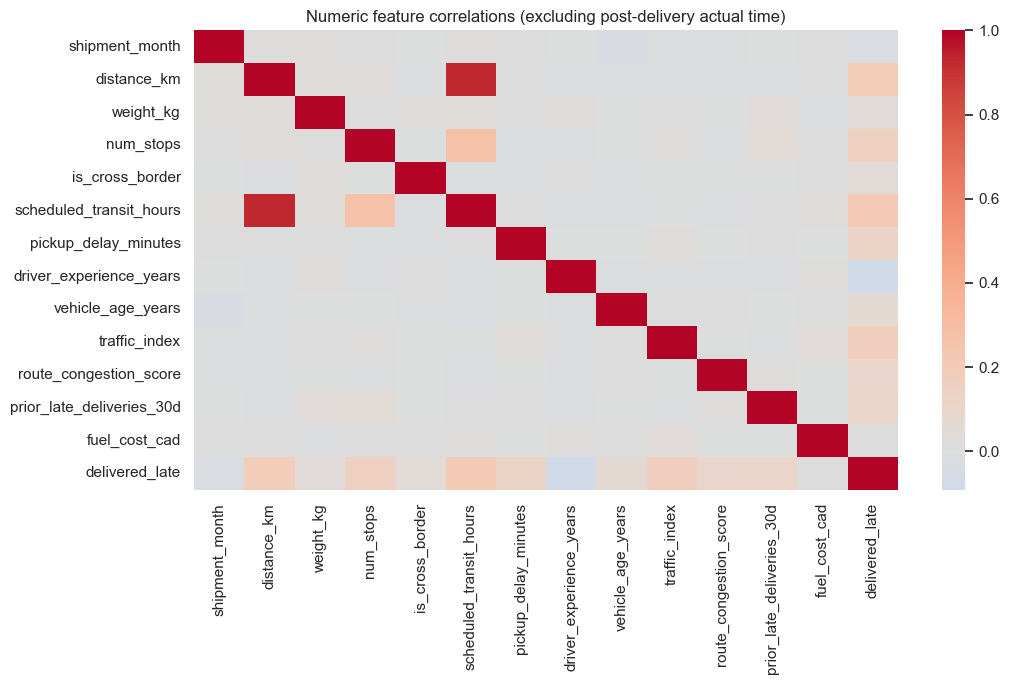

In [ ]:
numeric_eda = df.select_dtypes(include="number").drop(columns=["actual_transit_hours"], errors="ignore")
plt.figure(figsize=(11,7))
sns.heatmap(numeric_eda.corr(), cmap="coolwarm", center=0)
plt.title("Numeric feature correlations (excluding post-delivery actual time)")
plt.tight_layout(); plt.show()

###  Weather Conditions and Delivery Delays

The weather analysis shows a clear difference in late-delivery rates across different weather conditions.

- Storm: **46.4%** late deliveries.
- Snow: **33.7%** late deliveries.
- Fog: **21.0%** late deliveries.
- Rain: **20.7%** late deliveries.
- Clear weather: **14.1%** late deliveries.

Stormy weather has the highest late-delivery rate, followed by snow. Clear weather has the lowest late-delivery rate.

This suggests that difficult weather conditions are associated with a greater risk of delivery delays.

**Business recommendation:** MapleFreight should monitor weather forecasts and consider allowing additional delivery time during storms and snowfall. This could help dispatch teams prepare for possible delays in advance.

###  Carrier Performance

The carrier analysis shows that delivery performance varies between carriers.

The late-delivery rates are:

- Contract owner-operators: **36.1%**
- PrairieLine: **26.4%**
- QuebecExpress: **22.4%**
- NorthStar Carriers: **22.0%**
- MapleFreight Fleet: **12.8%**

Contract owner-operators have the highest late-delivery rate, while MapleFreight Fleet has the lowest.

This suggests that carrier selection may be an important factor when predicting delivery delays.

**Business recommendation:** MapleFreight should review the performance of carriers with higher delay rates and investigate possible reasons, such as route difficulty, scheduling, or operational issues.

These results show an association between carrier and delay risk, but they do not prove that the carrier itself causes the delays.

###  Service Level and Delivery Performance

The service-level analysis compares Economy, Standard, and Express shipments.

The results show:

- Economy: **26.6%** late deliveries.
- Standard: **20.7%** late deliveries.
- Express: **15.1%** late deliveries.

Economy shipments have the highest late-delivery rate, while Express shipments have the lowest.

This suggests that service level is related to delivery performance. Express shipments may receive different scheduling or operational priority.

**Business recommendation:** MapleFreight should review the scheduling and routing of Economy shipments to identify opportunities for improvement.

###  Customer Priority Tier

The analysis compares delivery delays for Gold, Silver, and Bronze customers.

The late-delivery rates are:

- Gold: **20.7%**
- Bronze: **20.7%**
- Silver: **20.4%**

The percentages are very similar across all three customer priority tiers.

This suggests that customer priority tier has little visible relationship with late-delivery rates in this dataset.

Based on these results, customer priority tier does not appear to be a major factor in explaining delivery delays.

### Numerical Feature Analysis

The correlation heatmap shows the relationships between numerical variables in the dataset.

Correlation values closer to 1 indicate a positive relationship, values closer to -1 indicate a negative relationship, and values near 0 indicate a weak linear relationship.

The numerical analysis helps us investigate whether factors such as traffic congestion, route distance, number of stops, and pickup delays are related to delivery outcomes.

The distribution graphs also help identify unusual values and differences between numerical features.

This analysis is useful for understanding the dataset before model training. However, correlation does not prove that one variable causes another variable to change.

## 6. Feature engineering and leakage prevention

In [ ]:
df["route"] = df["origin_city"].fillna("unknown") + " → " + df["destination_city"].fillna("unknown")
df["scheduled_speed_kmh"] = df["distance_km"] / df["scheduled_transit_hours"].replace(0, np.nan)
df["pickup_late_flag"] = (df["pickup_delay_minutes"] > 0).astype(int)
# Do NOT use shipment_id or actual_transit_hours as predictors.
X = df.drop(columns=["shipment_id", "actual_transit_hours", "delivered_late"])
y = df["delivered_late"].astype(int)
print("Features:", X.shape[1]); print("Late rate:", round(y.mean(), 3))

Features: 23
Late rate: 0.206


###  Feature Engineering

I created additional features to help the machine learning models identify patterns in delivery delays.

The new features include route information, scheduled travel speed, and a flag indicating whether pickup was late.

These features may provide useful information about route difficulty, delivery schedules, and pickup performance.

I also removed `actual_transit_hours` from the model input because this information is only available after the shipment has been delivered.

Using this column would cause **data leakage**, meaning the model would use information that would not be available when making a real prediction.

After feature engineering, the model input contained **23 features**.

This step helped prepare the data for realistic delivery-delay prediction.

## 7. Train, validation and test sets
Split before fitting imputers, encoders or models. The validation set is for choosing the alert threshold; the test set is for final evaluation only. Since this dataset has no usable shipment dates, a stratified random split is used; real deployment should use a time-based split.

In [ ]:
from sklearn.model_selection import train_test_split
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)
print("Train/validation/test:", len(X_train), len(X_val), len(X_test))

Train/validation/test: 3597 1200 1200


### Data Splitting

I divided the cleaned dataset into three parts:

- Training data: **3,597 shipments**
- Validation data: **1,200 shipments**
- Testing data: **1,200 shipments**

The training dataset was used to teach the machine learning models.

The validation dataset was used to compare models and select the alert threshold.

The testing dataset was kept separate until the final evaluation to check how well the selected model performs on unseen data.

I used stratified splitting to maintain a similar proportion of late and on-time deliveries in each dataset.

This approach helps provide a fairer evaluation of the machine learning models.

## 8. Baseline and improved models

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random forest": Pipeline([("prep", preprocess), ("model", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1))])
}
for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    print("Trained:", name)

Trained: Dummy baseline
Trained: Logistic regression
Trained: Random forest


## 9. Compare models on validation data

In [ ]:
def metric_row(name, actual, predicted):
    return {"model":name, "accuracy":accuracy_score(actual,predicted), "precision":precision_score(actual,predicted,zero_division=0), "recall":recall_score(actual,predicted,zero_division=0), "f1":f1_score(actual,predicted,zero_division=0)}
rows=[]
for name, estimator in models.items():
    rows.append(metric_row(name, y_val, estimator.predict(X_val)))
comparison = pd.DataFrame(rows).sort_values("f1", ascending=False)
display(comparison.round(3))

,model,accuracy,precision,recall,f1
1,Logistic regression,0.748,0.429,0.684,0.527
2,Random forest,0.811,0.593,0.259,0.361
0,Dummy baseline,0.794,0.000,0.000,0.000


### Model Comparison

I trained and compared three machine learning models: Dummy Classifier, Logistic Regression, and Random Forest.

The Dummy Classifier achieved 79.4% accuracy, but its recall and F1-score were both 0%. This means it failed to identify late deliveries.

Random Forest achieved the highest accuracy of 81.1% and precision of 59.3%. However, its recall was only 25.9%, meaning it missed many late shipments.

Logistic Regression achieved 68.4% recall and an F1-score of 52.7%. Although its accuracy was lower than Random Forest, it identified more late deliveries.

**I selected Logistic Regression as the final model** because identifying late shipments is more important for this business problem than achieving high accuracy alone.

This model can help dispatch teams identify shipments at risk before delivery deadlines are missed.

## 10. Choose an alert threshold using validation data only
Select the Logistic Regression or Random Forest model based on validation F1, then compare thresholds. This example chooses the threshold with the highest F1 among those achieving at least 50% recall (if possible). This is an illustrative dispatch policy.

In [ ]:
candidate_names = ["Logistic regression", "Random forest"]
best_name = comparison[comparison.model.isin(candidate_names)].iloc[0]["model"]
final_model = models[best_name]
val_probs = final_model.predict_proba(X_val)[:,1]
threshold_rows=[]
for t in np.arange(0.20, 0.81, 0.05):
    row=metric_row(best_name, y_val, (val_probs >= t).astype(int))
    row["threshold"] = round(float(t),2)
    row["alert_count"] = int((val_probs >= t).sum())
    threshold_rows.append(row)
threshold_table=pd.DataFrame(threshold_rows)
display(threshold_table[["threshold", "precision", "recall", "f1", "alert_count"]].round(3))
eligible = threshold_table[threshold_table.recall >= 0.50]
selection = eligible if not eligible.empty else threshold_table
chosen = selection.sort_values(["f1","precision"], ascending=False).iloc[0]
threshold=float(chosen.threshold)
print("Selected model:", best_name, "| threshold:", threshold, "| validation alerts:", int(chosen.alert_count))

,threshold,precision,recall,f1,alert_count
0,0.20,0.286,0.951,0.439,823
1,0.25,0.312,0.923,0.466,731
2,0.30,0.332,0.874,0.482,650
3,0.35,0.361,0.850,0.507,581
4,0.40,0.387,0.802,0.522,512
5,0.45,0.411,0.733,0.527,440
6,0.50,0.429,0.684,0.527,394
7,0.55,0.482,0.656,0.556,336
8,0.60,0.498,0.599,0.544,297
9,0.65,0.534,0.543,0.538,251


Selected model: Logistic regression | threshold: 0.55 | validation alerts: 336


###  Alert Threshold Selection

I tested different probability thresholds to decide when the system should classify a shipment as high risk.

The thresholds ranged from 0.20 to 0.80.

Based on the validation results, the threshold of **0.55 (55%)** achieved the highest F1-score of approximately 0.556 among the tested values.

At this threshold:

- Precision: 48.2%
- Recall: 65.6%
- F1-score: 55.6%
- High-risk alerts: 336 validation shipments

I selected 0.55 because it provides a reasonable balance between identifying late deliveries and reducing unnecessary alerts.

A lower threshold would identify more late shipments but also generate more false alerts. A higher threshold would reduce the number of alerts but could miss more actual delays.

Therefore, 0.55 was selected for the final model evaluation and Slack alert demonstration.

## 11. Final untouched test evaluation

Final model: Logistic regression | Threshold: 0.55


,model,accuracy,precision,recall,f1
0,Dummy baseline,0.794,0.00,0.000,0.000
1,Logistic regression (selected threshold),0.777,0.47,0.656,0.547


              precision    recall  f1-score   support

           0       0.90      0.81      0.85       953
           1       0.47      0.66      0.55       247

    accuracy                           0.78      1200
   macro avg       0.69      0.73      0.70      1200
weighted avg       0.81      0.78      0.79      1200



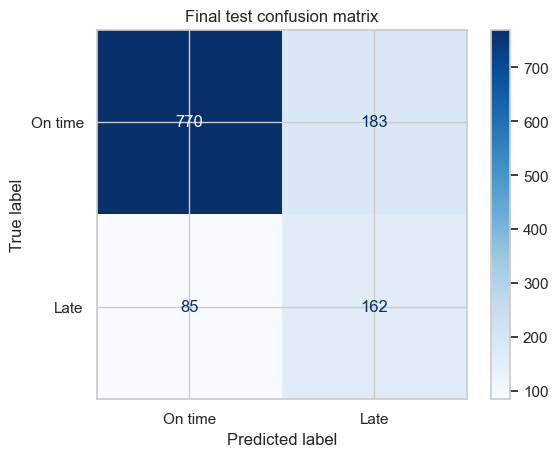

In [ ]:
test_probs = final_model.predict_proba(X_test)[:,1]
test_pred = (test_probs >= threshold).astype(int)
print("Final model:", best_name, "| Threshold:", threshold)
display(pd.DataFrame([metric_row("Dummy baseline",y_test,models["Dummy baseline"].predict(X_test)), metric_row(best_name+" (selected threshold)",y_test,test_pred)]).round(3))
print(classification_report(y_test, test_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["On time", "Late"], cmap="Blues")
plt.title("Final test confusion matrix"); plt.show()

###  Final Model Evaluation

After selecting Logistic Regression and the 0.55 threshold, I evaluated the model using the untouched test dataset.

The final model achieved:

- Accuracy: **77.7%**
- Precision: **47.0%**
- Recall: **65.6%**
- F1-score: **54.7%**

The recall score means that the model successfully identified approximately 66% of the shipments that were actually delivered late.

The precision score means that approximately 47% of shipments predicted as late were actually late.

The confusion matrix shows the number of correct and incorrect predictions, including false alarms and missed late deliveries.

Compared with the baseline model, Logistic Regression provides much better identification of late shipments.

Although the model is not perfect, it provides useful early-warning information that can help dispatch teams make better decisions.

Further improvements could include collecting more real-time traffic information and testing additional machine learning models.

## 12. Model explainability

,permutation_importance
carrier,0.047198
weather_condition,0.044125
traffic_index,0.041453
num_stops,0.036711
distance_km,0.007417
is_cross_border,0.004875
driver_experience_years,0.002036
prior_late_deliveries_30d,0.001199
weight_kg,0.000273
scheduled_transit_hours,-0.000998


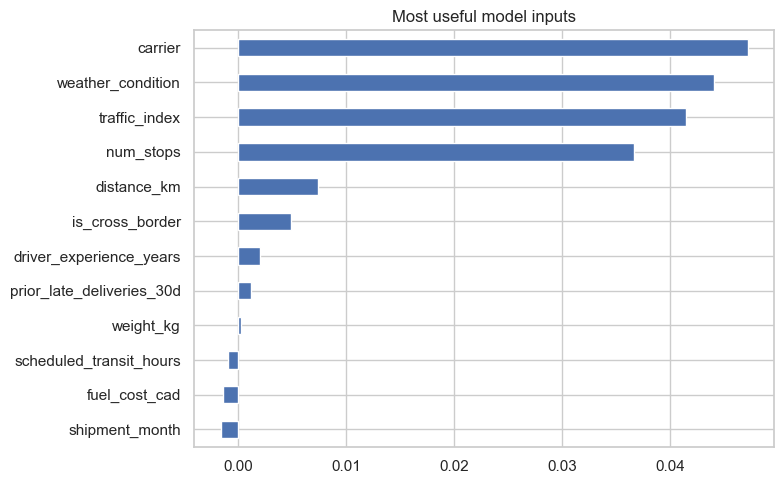

In [ ]:
from sklearn.inspection import permutation_importance
# Permutation importance on held-out validation rows, scored using late-class F1 at 0.5.
permutation = permutation_importance(final_model, X_val, y_val, n_repeats=3, random_state=RANDOM_STATE, scoring="f1", n_jobs=1)
importance = pd.Series(permutation.importances_mean, index=X_val.columns).sort_values(ascending=False)
display(importance.head(12).to_frame("permutation_importance"))
importance.head(12).sort_values().plot(kind="barh", figsize=(8,5), title="Most useful model inputs")
plt.tight_layout(); plt.show()

### Model Explainability

I used permutation importance to understand which features were most useful for the final Logistic Regression model.

The four most important features were:

1. Carrier
2. Weather condition
3. Traffic index
4. Number of stops

Carrier had the highest importance score, followed by weather conditions, traffic congestion, and number of stops.

These results suggest that delivery performance is influenced by a combination of carrier operations, weather conditions, and route characteristics.

The feature importance results also support some patterns observed during exploratory data analysis.

**Business recommendation:** MapleFreight should focus on monitoring carrier performance, weather forecasts, traffic conditions, and complex routes with multiple stops.

Permutation importance measures how much the model relies on each feature for prediction. It does not prove that a feature directly causes delays.

## 13. Slack alerts — real webhook integration
Create Slack channel `#dispatch-alerts`, enable Incoming Webhooks for your Slack app, and save the URL in `.env` as `SLACK_WEBHOOK_URL=...`. **Never commit `.env`, show the URL in output, or share it.**

This demonstration scores held-out historical shipments. For production, score **current in-transit shipments** and avoid sending repeated alerts for the same shipment. The next cell prepares the alert message; the following cell only sends when you explicitly set `SEND_SLACK_ALERT = True`.

In [ ]:
alerts = df.loc[X_test.index, ["shipment_id", "destination_city", "carrier"]].copy()
alerts["risk_score"] = test_probs
high_risk = alerts[alerts.risk_score >= threshold].sort_values("risk_score", ascending=False)
print("High-risk shipments:", len(high_risk))
display(high_risk.head(10))
message = f"🚨 MapleFreight Delivery Risk Alert\nHigh-risk shipments: {len(high_risk)}\n\n"
for _, shipment in high_risk.head(5).iterrows():
    message += (f"ID: {shipment['shipment_id']} | Destination: {shipment['destination_city']}\n"
                f"Carrier: {shipment['carrier']} | Risk: {shipment['risk_score']:.1%}\n\n")
print("Alert preview (no secrets):\n", message)

High-risk shipments: 345


,shipment_id,destination_city,carrier,risk_score
1726,SHP-105478,hamilton on,contract owner-op,0.984961
4615,SHP-103231,winnipeg mb,contract owner-op,0.984397
956,SHP-101710,sudbury on,maplefreight fleet,0.981639
2354,SHP-101528,calgary ab,prairieline,0.978823
940,SHP-101673,sudbury on,contract owner-op,0.975640
3626,SHP-100161,calgary ab,contract owner-op,0.973911
3757,SHP-101613,quebec city qc,contract owner-op,0.973836
3645,SHP-100273,hamilton on,northstar carriers,0.970312
700,SHP-101676,ottawa on,quebecexpress,0.969454
2462,SHP-101369,montreal qc,prairieline,0.967703


Alert preview (no secrets):
 🚨 MapleFreight Delivery Risk Alert
High-risk shipments: 345

ID: SHP-105478 | Destination: hamilton on
Carrier: contract owner-op | Risk: 98.5%

ID: SHP-103231 | Destination: winnipeg mb
Carrier: contract owner-op | Risk: 98.4%

ID: SHP-101710 | Destination: sudbury on
Carrier: maplefreight fleet | Risk: 98.2%

ID: SHP-101528 | Destination: calgary ab
Carrier: prairieline | Risk: 97.9%

ID: SHP-101673 | Destination: sudbury on
Carrier: contract owner-op | Risk: 97.6%




###  Slack Alert Integration

I developed a Slack alert system to notify the dispatch team about shipments that have a high predicted risk of late delivery.

Using the selected threshold of 0.55, the model identified **345 high-risk shipments** in the test dataset.

The alert message was designed to include:

- Total number of high-risk shipments.
- Shipment ID.
- Destination city.
- Carrier name.
- Predicted delay risk score.

This information helps the dispatch team quickly identify which shipments may require attention.

The Slack integration uses an Incoming Webhook, and the webhook URL is stored securely in a `.env` file.

**Current status:** The alert message has been prepared, but actual Slack sending is currently disabled. I still need to configure the webhook, send the message, and save a screenshot of the notification.

Once connected, this system can support earlier intervention, better communication, and improved delivery planning.

In [ ]:
%pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import requests
from dotenv import load_dotenv
load_dotenv()
SEND_SLACK_ALERT = False  # Change to True only after configuring your Slack webhook.
if SEND_SLACK_ALERT:
    webhook_url = os.getenv("SLACK_WEBHOOK_URL")
    if not webhook_url:
        raise ValueError("SLACK_WEBHOOK_URL is missing from .env")
    if high_risk.empty:
        print("No high-risk shipments; no alert sent.")
    else:
        response = requests.post(webhook_url, json={"text":message}, timeout=15)
        response.raise_for_status()
        print("Slack alert sent. Save a real screenshot as screenshots/slack_alert.png")
else:
    print("Slack send disabled. Set SEND_SLACK_ALERT=True after adding your webhook.")

Slack send disabled. Set SEND_SLACK_ALERT=True after adding your webhook.


## 14. Recommendations and conclusion
### Business Recommendations

Based on the exploratory data analysis and machine learning results, I recommend the following actions for MapleFreight Logistics.

**1. Improve carrier performance**

Contract owner-operators had the highest late-delivery rate at 36.1%. MapleFreight should review carrier performance regularly and investigate why some carriers experience more delays.

**2. Monitor weather conditions**

Storms and snow were associated with higher late-delivery rates. The company should monitor weather forecasts and prepare alternative delivery plans during difficult weather conditions.

**3. Improve traffic and route planning**

Traffic index and number of stops were important features in the prediction model. Dispatch teams should consider traffic conditions and route complexity when planning deliveries.

**4. Use predictive Slack alerts**

The machine learning model can identify high-risk shipments before delivery is completed. Slack alerts can help dispatch teams review these shipments and take action earlier.

**5. Monitor model performance**

MapleFreight should regularly evaluate precision, recall, and F1-score to ensure the model continues to provide useful predictions.

### Conclusion

In this project, I developed a machine learning approach to predict late deliveries for MapleFreight Logistics.

I cleaned the dataset, performed exploratory data analysis, created new features, and compared different machine learning models.

Logistic Regression was selected as the final model because it provided better recall and F1-score than the other tested models at their default thresholds.

The final model achieved **77.7% accuracy, 65.6% recall, and a 54.7% F1-score** using a 0.55 alert threshold.

The project also prepared a Slack alert system to notify dispatch about high-risk shipments.

Overall, the results show that machine learning can support earlier detection of delivery risks and help MapleFreight make more informed operational decisions. However, the model's real-world business impact would need to be measured after deployment.